In [102]:
import pandas as pd
import matplotlib.pyplot as plt

In [103]:
df = pd.read_csv('data/stage.csv')

## Visualizing an event sequence with mplsoccer

In [104]:
from mplsoccer import Pitch
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

HOME_COLOR = 'crimson'
AWAY_COLOR = 'royalblue'
FAIL_EDGE = 'black'
SUCCESS_EDGE = 'white'

In [105]:
def animate_sequence(df, game_id, start_idx=0, n_events=15, interval=800):
    """Animate a slice of events from one game on a pitch.

    Each event has only a start (x, y) — no end location — so the line
    between consecutive events approximates ball movement as "where the
    ball was next", not the true trajectory of the action itself.
    """
    seq = (
        df[df.game_id == game_id]
        .iloc[start_idx:start_idx + n_events]
        .reset_index(drop=True)
    )

    pitch = Pitch(pitch_type='uefa')
    fig, ax = pitch.draw(figsize=(10.4, 6.8))

    path_line, = ax.plot([], [], color='grey', linewidth=1.5, alpha=0.6, zorder=1)
    trail_scatter = ax.scatter([], [], s=80, zorder=2)
    current_scatter = ax.scatter([], [], s=260, zorder=3, linewidths=2)
    label = ax.text(52.5, 71, '', ha='center', va='bottom', fontsize=11)

    def update(i):
        events = seq.iloc[:i + 1]
        colors = [HOME_COLOR if home else AWAY_COLOR for home in events.is_home]

        path_line.set_data(events.start_x, events.start_y)
        trail_scatter.set_offsets(events[['start_x', 'start_y']].values)
        trail_scatter.set_color(colors)
        trail_scatter.set_alpha(0.35)

        current = seq.iloc[i]
        current_scatter.set_offsets([[current.start_x, current.start_y]])
        current_scatter.set_color(HOME_COLOR if current.is_home else AWAY_COLOR)
        current_scatter.set_edgecolor(SUCCESS_EDGE if current.result_name == 'success' else FAIL_EDGE)

        team = 'home' if current.is_home else 'away'
        label.set_text(
            f"{current.minute:02.0f}:{current.second:02.0f}  "
            f"{team}  {current.type_name} ({current.result_name})"
        )
        return path_line, trail_scatter, current_scatter, label

    return FuncAnimation(fig, update, frames=len(seq), interval=interval, blit=False, repeat=False)

In [106]:
df.head()

,Unnamed: 0,game_id,original_event_id,index,period_id,minute,second,duration,start_x,start_y,type_name,result_name,is_home,home_yellow_count,away_yellow_count,home_red_count,away_red_count,home_goal_count,away_goal_count
0,0,3754217,5f9bdb6d-0379-4f42-9f53-29777f166db5,5,1,0,0,0.386674,51.66875,34.0425,pass,success,False,0,0,0,0,0,0
1,1,3754217,e5d7db8c-d134-4392-a109-9f6efc7f7225,7,1,0,1,1.499254,53.15625,35.7425,pass,success,False,0,0,0,0,0,0
2,2,3754217,7ec3ada2-d200-4f0b-ab86-f5a464dc4aa7,9,1,0,2,2.672921,66.80625,32.4275,dribble,success,False,0,0,0,0,0,0
3,3,3754217,fd5039d0-8dd4-417c-9eac-decd2d267e93,10,1,0,5,0.986454,61.73125,35.4025,pass,success,False,0,0,0,0,0,0
4,4,3754217,d8a6875b-79c2-4f3b-bb08-38cda23763ec,12,1,0,6,0.851193,49.83125,41.5225,dribble,success,False,0,0,0,0,0,0


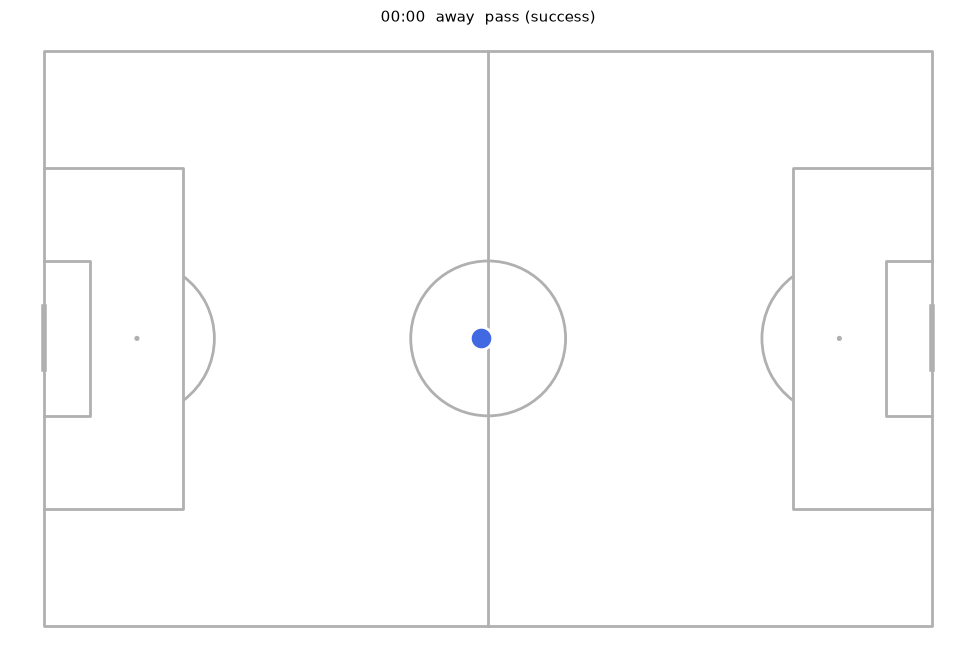

In [107]:
anim = animate_sequence(df, game_id=df.game_id.iloc[0], start_idx=0, n_events=100)
HTML(anim.to_jshtml())

## Step through a sequence one event at a time

In [108]:
import ipywidgets as widgets
from IPython.display import display


def step_through_sequence(df, game_id, start_idx=0, n_events=15):
    """Same sequence view as animate_sequence, but advanced manually via
    Next/Previous buttons instead of autoplaying.

    The pitch and artists are built once and updated in place on each
    click (same approach as animate_sequence's FuncAnimation update) —
    redrawing the whole pitch from scratch per click is what made the
    first version of this feel slow.
    """
    seq = (
        df[df.game_id == game_id]
        .iloc[start_idx:start_idx + n_events]
        .reset_index(drop=True)
    )

    pitch = Pitch(pitch_type='uefa')
    fig, ax = pitch.draw(figsize=(10.4, 6.8))
    plt.close(fig)  # detach from pyplot's auto-display; we show it manually below

    # Home always attacks toward increasing x in this dataset (verified across
    # all games) — SPADL doesn't preserve the real-pitch swap at half time.
    arrow_y = 69.3
    ax.annotate('', xy=(35, arrow_y), xytext=(8, arrow_y),
                arrowprops=dict(arrowstyle='-|>', color=HOME_COLOR, lw=2.5))
    ax.text(21.5, arrow_y + 1.3, 'HOME', color=HOME_COLOR, ha='center', va='bottom',
            fontsize=9, fontweight='bold')
    ax.annotate('', xy=(70, arrow_y), xytext=(97, arrow_y),
                arrowprops=dict(arrowstyle='-|>', color=AWAY_COLOR, lw=2.5))
    ax.text(83.5, arrow_y + 1.3, 'AWAY', color=AWAY_COLOR, ha='center', va='bottom',
            fontsize=9, fontweight='bold')

    path_line, = ax.plot([], [], color='grey', linewidth=1.5, alpha=0.6, zorder=1)
    trail_scatter = ax.scatter([], [], s=80, zorder=2)
    current_scatter = ax.scatter([], [], s=260, zorder=3, linewidths=2)
    label = ax.text(52.5, 71, '', ha='center', va='bottom', fontsize=11)

    out = widgets.Output()
    state = {'i': 0}

    def render():
        events = seq.iloc[:state['i'] + 1]
        colors = [HOME_COLOR if home else AWAY_COLOR for home in events.is_home]

        path_line.set_data(events.start_x, events.start_y)
        trail_scatter.set_offsets(events[['start_x', 'start_y']].values)
        trail_scatter.set_color(colors)
        trail_scatter.set_alpha(0.35)

        current = seq.iloc[state['i']]
        current_scatter.set_offsets([[current.start_x, current.start_y]])
        current_scatter.set_color(HOME_COLOR if current.is_home else AWAY_COLOR)
        current_scatter.set_edgecolor(SUCCESS_EDGE if current.result_name == 'success' else FAIL_EDGE)

        team = 'home' if current.is_home else 'away'
        label.set_text(
            f"{current.minute:02.0f}:{current.second:02.0f}  {team}  "
            f"{current.type_name} ({current.result_name})  [{state['i'] + 1}/{len(seq)}]"
        )

        with out:
            out.clear_output(wait=True)
            display(fig)

    next_btn = widgets.Button(description='Next event ▶')
    prev_btn = widgets.Button(description='◀ Previous')

    def on_next(_):
        state['i'] = min(state['i'] + 1, len(seq) - 1)
        render()

    def on_prev(_):
        state['i'] = max(state['i'] - 1, 0)
        render()

    next_btn.on_click(on_next)
    prev_btn.on_click(on_prev)

    render()
    display(widgets.HBox([prev_btn, next_btn]), out)

In [109]:
game_ids = df['game_id'].unique()

In [110]:
df.game_id.iloc[0]

3754217

In [111]:
game_ids[0]

3754217

In [112]:
step_through_sequence(df, game_id=game_ids[10], n_events=100)

Output()

## Event locations by type, across all games

In [113]:
def plot_event_locations(df, event_types=('shot', 'pass', 'dribble', 'interception'), dense_threshold=50_000):
    """Plot every event of each type on its own pitch.

    Sparse event types (e.g. shots) are scattered and colored by outcome.
    Dense types (e.g. passes) are shown as a hexbin density heatmap instead —
    a raw scatter of hundreds of thousands of points just saturates into a
    solid blob and stops being informative.
    """
    pitch = Pitch(pitch_type='uefa')
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    for ax, event_type in zip(axes.flat, event_types):
        pitch.draw(ax=ax)
        events = df[df.type_name == event_type]

        if len(events) > dense_threshold:
            pitch.hexbin(events.start_x, events.start_y, ax=ax, gridsize=30, cmap='Greens', mincnt=1)
        else:
            colors = events.result_name.map({'success': 'seagreen'}).fillna('crimson')
            pitch.scatter(
                events.start_x, events.start_y, ax=ax,
                c=colors, s=8, alpha=0.25, edgecolors='none', rasterized=True,
            )
        ax.set_title(f'{event_type} (n={len(events):,})', fontsize=13)

    fig.suptitle('Event locations — sparse types: green=success/red=fail, dense types: density heatmap', fontsize=13)
    fig.tight_layout()
    return fig

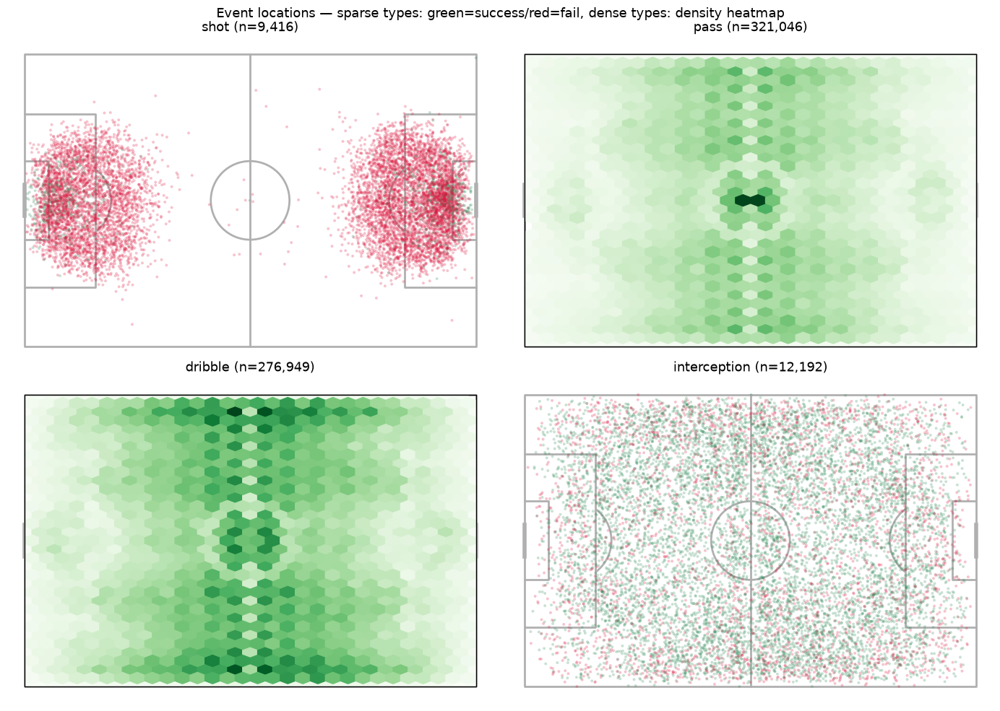

In [114]:
plot_event_locations(df)
plt.show()

## Interception grid heatmap

In [115]:
def plot_interception_grid(df, bins=(6, 4)):
    """Bin interceptions into a grid of squares, colored and labeled by
    the proportion of all interceptions that occurred in each square."""
    pitch = Pitch(pitch_type='uefa', line_zorder=2, line_color='black')
    fig, ax = pitch.draw(figsize=(10.4, 6.8))

    events = df[df.type_name == 'interception']
    stats = pitch.bin_statistic(events.start_x, events.start_y, statistic='count', bins=bins, normalize=True)

    pitch.heatmap(stats, ax=ax, cmap='Reds', edgecolor='white', alpha=0.75, zorder=1)
    pitch.label_heatmap(
        stats, ax=ax, str_format='{:.1%}',
        ha='center', va='center', color='black', fontsize=10, zorder=3,
    )
    ax.set_title(f'Interception location share (n={len(events):,})', fontsize=14)
    return fig

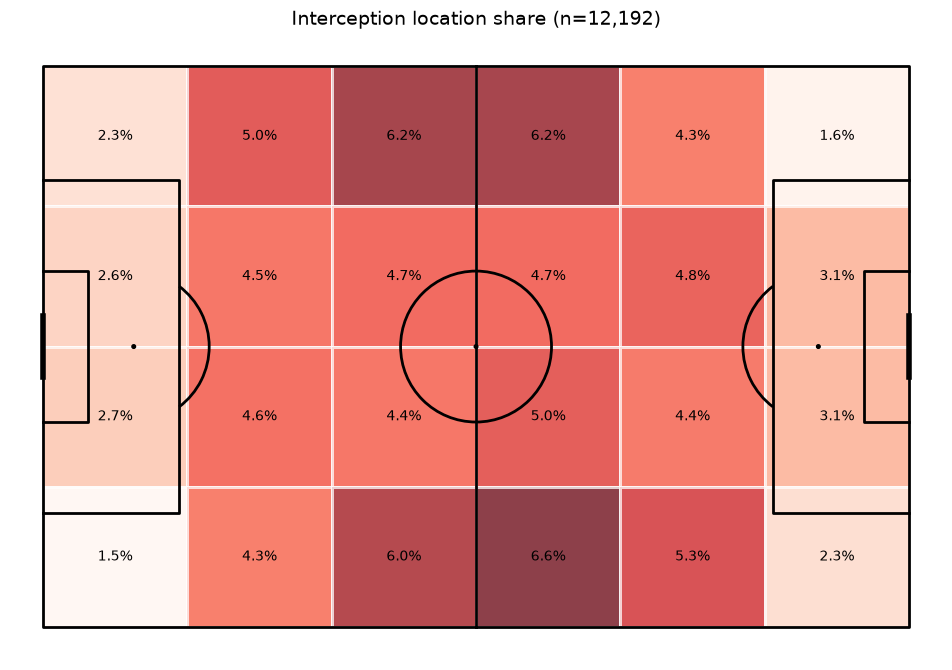

In [116]:
plot_interception_grid(df)
plt.show()

## Ball time heatmap

Where the ball spends the most time, using each event's `duration` as a proxy
for time-at-location (summed per grid cell, normalized to a proportion of
total event time across the dataset).

In [117]:
def plot_ball_time_heatmap(df, bins=(6, 4)):
    """Grid heatmap of the proportion of total ball time spent in each zone,
    using each event's duration as a proxy for how long the ball was there."""
    pitch = Pitch(pitch_type='uefa', line_zorder=2, line_color='black')
    fig, ax = pitch.draw(figsize=(10.4, 6.8))

    stats = pitch.bin_statistic(df.start_x, df.start_y, values=df.duration, statistic='sum', bins=bins, normalize=True)

    pitch.heatmap(stats, ax=ax, cmap='Blues', edgecolor='white', alpha=0.75, zorder=1)
    pitch.label_heatmap(
        stats, ax=ax, str_format='{:.1%}',
        ha='center', va='center', color='black', fontsize=10, zorder=3,
    )
    ax.set_title('Share of total ball time by pitch zone', fontsize=14)
    return fig

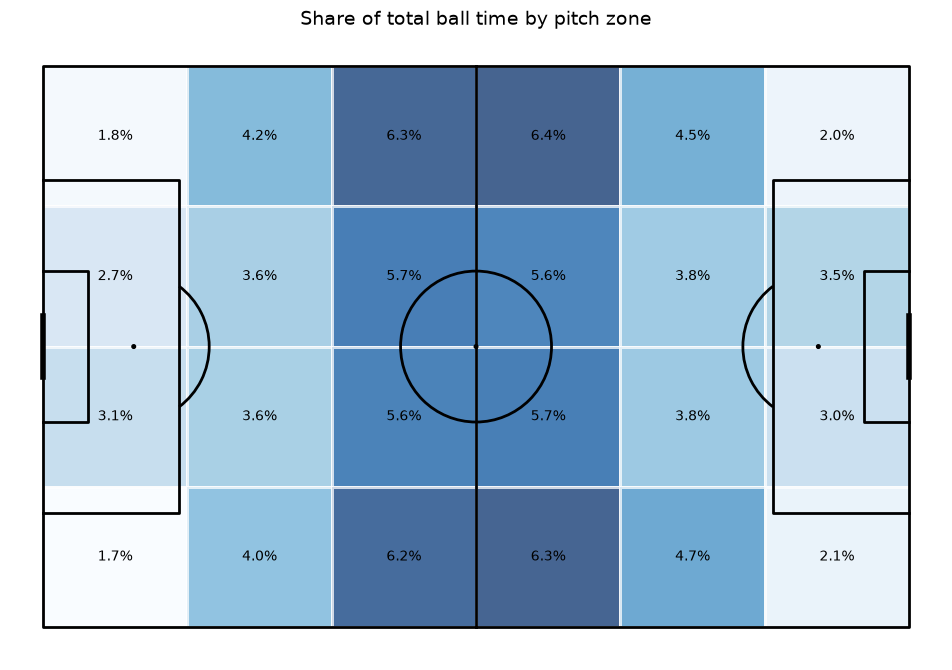

In [118]:
plot_ball_time_heatmap(df)
plt.show()

## Event-to-event transitions

What type of event tends to follow what. Transitions are computed within each
game only (sorted by `index`, the event order) — the event that starts a new
game is never paired with the last event of the previous one.

In [119]:
def event_transitions(df):
    """Pair each event with the event that immediately follows it, within the same game."""
    ordered = df.sort_values(['game_id', 'index'])
    next_type = ordered.groupby('game_id')['type_name'].shift(-1)
    pairs = ordered.assign(next_type_name=next_type).dropna(subset=['next_type_name'])
    return pairs[['game_id', 'type_name', 'next_type_name']]


transitions = event_transitions(df)
pair_counts = transitions.groupby(['type_name', 'next_type_name']).size().sort_values(ascending=False)
pair_counts.head(15)

type_name  next_type_name
pass       dribble           227238
dribble    pass              225159
pass       pass               57905
dribble    take_on            13436
pass       interception       10314
dribble    tackle             10155
pass       clearance           8754
throw_in   dribble             8540
tackle     dribble             8449
dribble    bad_touch           8336
take_on    dribble             8238
dribble    cross               7422
clearance  pass                7099
dribble    foul                7077
pass       throw_in            7060
dtype: int64

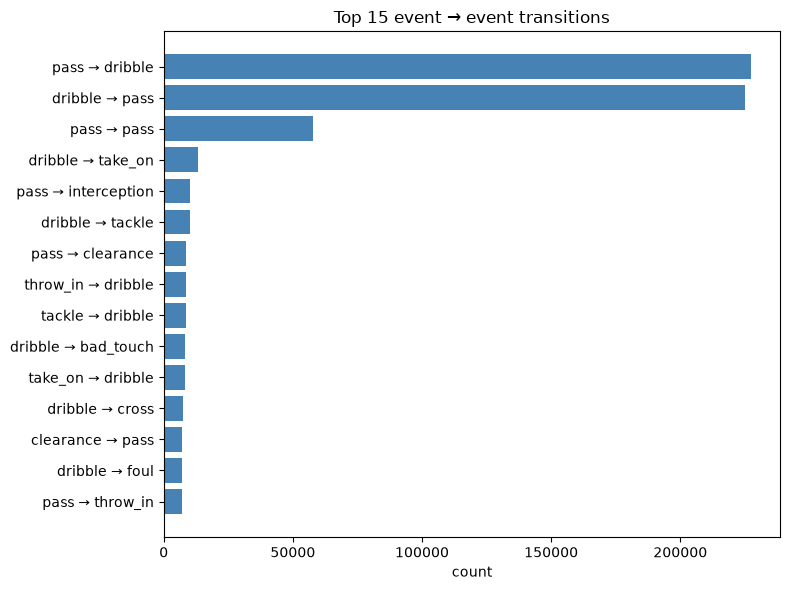

In [120]:
def plot_top_pairs(pair_counts, top_n=15):
    top = pair_counts.head(top_n).iloc[::-1]
    labels = [f'{a} → {b}' for a, b in top.index]

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(labels, top.values, color='steelblue')
    ax.set_xlabel('count')
    ax.set_title(f'Top {top_n} event → event transitions')
    fig.tight_layout()
    return fig


plot_top_pairs(pair_counts)
plt.show()

## Downstream event probabilities

For each event type, P(next event type | current event type) — each row sums to 100%.

In [121]:
transition_matrix = pd.crosstab(transitions.type_name, transitions.next_type_name, normalize='index')
transition_matrix

next_type_name,bad_touch,clearance,corner_crossed,corner_short,cross,dribble,foul,freekick_crossed,freekick_short,goalkick,...,keeper_claim,keeper_punch,keeper_save,pass,shot,shot_freekick,shot_penalty,tackle,take_on,throw_in
type_name,,,,,,,,,,,,,,,,,,,,,
bad_touch,0.000463,0.111841,0.003700,0.000740,0.000925,0.339315,0.020167,0.000185,0.000278,0.045143,...,0.002683,0.000185,0.00000,0.301480,0.005550,0.000000,0.000000,0.000463,0.000648,0.153377
clearance,0.002176,0.083140,0.041107,0.007546,0.002731,0.300991,0.017961,0.000463,0.000463,0.005416,...,0.001204,0.001435,0.00000,0.328627,0.021387,0.000000,0.000000,0.000370,0.000370,0.174058
corner_crossed,0.019656,0.495393,0.000614,0.000307,0.004300,0.054975,0.002457,0.000000,0.000000,0.021192,...,0.054361,0.065111,0.00000,0.076167,0.199631,0.000000,0.000000,0.000000,0.000000,0.003993
corner_short,0.005208,0.082031,0.002604,0.000000,0.055990,0.554688,0.002604,0.000000,0.000000,0.001302,...,0.000000,0.001302,0.00000,0.234375,0.037760,0.000000,0.000000,0.002604,0.003906,0.001302
cross,0.013292,0.404300,0.003699,0.000809,0.003236,0.176607,0.002890,0.005548,0.002080,0.055710,...,0.052358,0.018146,0.00000,0.081022,0.130490,0.000000,0.000000,0.000116,0.000000,0.016875
dribble,0.030104,0.000267,0.000007,0.000000,0.026803,0.000878,0.025557,0.000000,0.000004,0.000018,...,0.000022,0.000007,0.00000,0.813113,0.017031,0.000000,0.000000,0.036673,0.048521,0.000246
foul,0.000527,0.000316,0.000000,0.000000,0.000632,0.111884,0.007796,0.420143,0.375158,0.000000,...,0.000105,0.000000,0.00000,0.024863,0.000948,0.042246,0.009587,0.000316,0.001159,0.004003
freekick_crossed,0.023844,0.315519,0.000617,0.000000,0.004111,0.112230,0.007605,0.008222,0.004728,0.030421,...,0.020761,0.012539,0.00000,0.360329,0.048510,0.000000,0.000000,0.003289,0.003083,0.026310
freekick_short,0.003854,0.005780,0.000000,0.000000,0.007948,0.459056,0.005299,0.000963,0.000000,0.000723,...,0.000241,0.000000,0.00000,0.491570,0.013006,0.000000,0.000000,0.003131,0.004335,0.000963


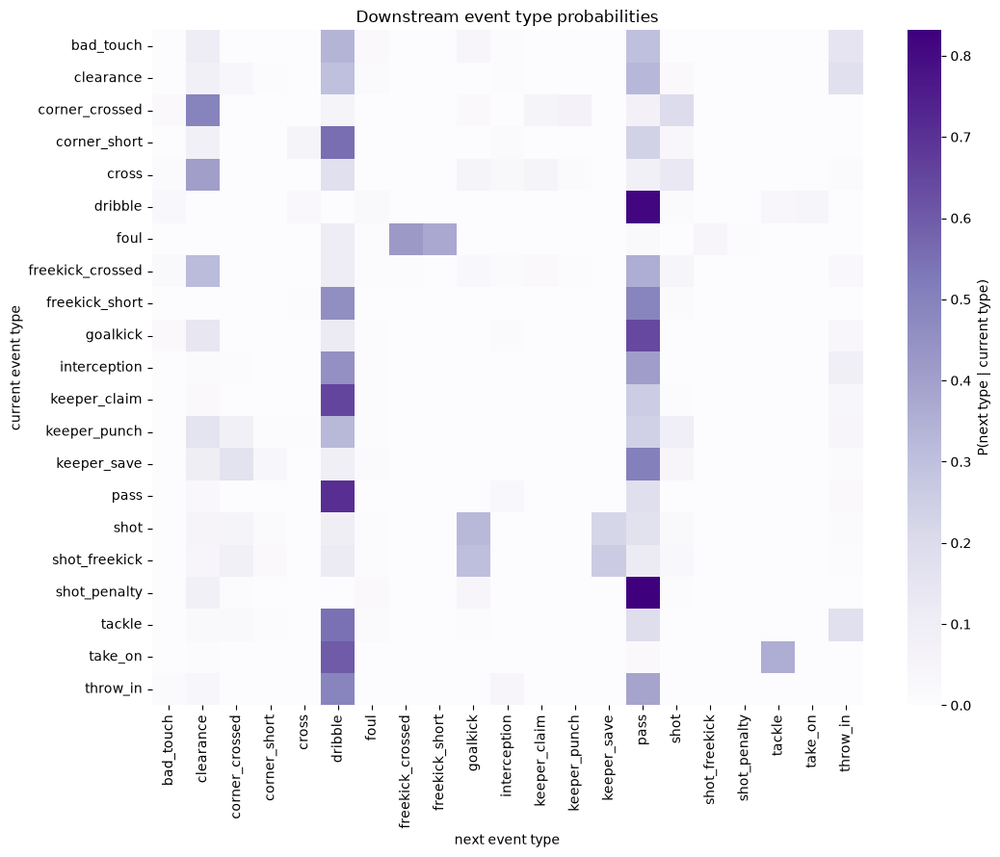

In [122]:
import seaborn as sns

def plot_transition_matrix(matrix):
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(matrix, cmap='Purples', annot=False, cbar_kws={'label': 'P(next type | current type)'}, ax=ax)
    ax.set_xlabel('next event type')
    ax.set_ylabel('current event type')
    ax.set_title('Downstream event type probabilities')
    fig.tight_layout()
    return fig


plot_transition_matrix(transition_matrix)
plt.show()

In [123]:
def top_downstream_types(matrix, top_k=3):
    """For each event type, its top_k most likely next event types with probabilities."""
    rows = {}
    for event_type, row in matrix.iterrows():
        top = row.sort_values(ascending=False).head(top_k)
        rows[event_type] = ', '.join(f'{t} ({p:.0%})' for t, p in top.items())
    return pd.Series(rows, name=f'top {top_k} downstream types')


top_downstream_types(transition_matrix)

bad_touch                   dribble (34%), pass (30%), throw_in (15%)
clearance                   pass (33%), dribble (30%), throw_in (17%)
corner_crossed                 clearance (50%), shot (20%), pass (8%)
corner_short                dribble (55%), pass (23%), clearance (8%)
cross                      clearance (40%), dribble (18%), shot (13%)
dribble                         pass (81%), take_on (5%), tackle (4%)
foul                freekick_crossed (42%), freekick_short (38%), ...
freekick_crossed           pass (36%), clearance (32%), dribble (11%)
freekick_short                   pass (49%), dribble (46%), shot (1%)
goalkick                   pass (64%), clearance (14%), dribble (12%)
interception                 dribble (45%), pass (41%), throw_in (9%)
keeper_claim                 dribble (65%), pass (26%), throw_in (4%)
keeper_punch               dribble (33%), pass (24%), clearance (16%)
keeper_save         pass (51%), corner_crossed (17%), clearance (10%)
pass                

## Timing per event type

Mean action duration and mean time elapsed since the previous event, broken
down by event type.

In [124]:
def event_type_timing_stats(df):
    """Mean duration and mean time elapsed since the previous event, per event type.

    Time elapsed is computed within each (game, period) so halftime breaks
    aren't counted as a gap; each period's first event has no prior event to
    compare against and is excluded.
    """
    d = df.sort_values(['game_id', 'period_id', 'index']).copy()
    d['timestamp'] = d.minute * 60 + d.second
    d['prev_timestamp'] = d.groupby(['game_id', 'period_id'])['timestamp'].shift(1)
    d['time_elapsed'] = d['timestamp'] - d['prev_timestamp']

    return d.groupby('type_name').agg(
        mean_duration=('duration', 'mean'),
        mean_time_elapsed=('time_elapsed', 'mean'),
        n=('type_name', 'size'),
    ).sort_values('mean_time_elapsed', ascending=False)


event_type_timing_stats(df)

,mean_duration,mean_time_elapsed,n
type_name,,,
shot_freekick,0.878397,64.805486,401
shot_penalty,0.512461,64.604396,91
freekick_crossed,2.886462,37.450256,4875
goalkick,3.290665,30.564140,6174
corner_crossed,1.809158,29.909119,3257
corner_short,1.369986,24.322122,773
freekick_short,1.601188,20.302236,4159
throw_in,1.528968,16.586276,17357
foul,0.002937,3.521552,9512


## Possession transitions (is_home)

P(next event's team | current event's team) — same within-game transition
logic as the event-type transitions above.

In [125]:
def is_home_transitions(df):
    """Pair each event's team (is_home) with the team of the event that
    immediately follows it, within the same game."""
    ordered = df.sort_values(['game_id', 'index'])
    next_is_home = ordered.groupby('game_id')['is_home'].shift(-1)
    pairs = ordered.assign(next_is_home=next_is_home).dropna(subset=['next_is_home'])
    return pairs[['game_id', 'is_home', 'next_is_home']]


home_transitions = is_home_transitions(df)
is_home_matrix = pd.crosstab(home_transitions.is_home, home_transitions.next_is_home, normalize='index')
is_home_matrix

next_is_home,False,True
is_home,,
False,0.786125,0.213875
True,0.201021,0.798979


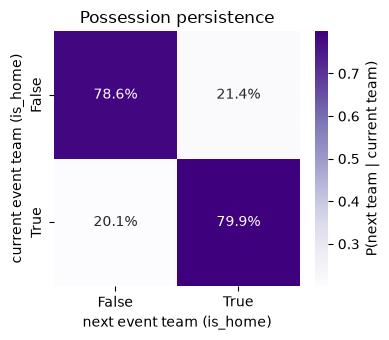

In [126]:
fig, ax = plt.subplots(figsize=(4, 3.5))
sns.heatmap(is_home_matrix, cmap='Purples', annot=True, fmt='.1%', cbar_kws={'label': 'P(next team | current team)'}, ax=ax)
ax.set_xlabel('next event team (is_home)')
ax.set_ylabel('current event team (is_home)')
ax.set_title('Possession persistence')
fig.tight_layout()
plt.show()

## Click a pitch square: where did the previous/next event happen?

Grids the pitch, and for a chosen square shows where the *previous* event
tended to occur and where the *next* event tends to occur, given the current
event happened in that square.

Note on interaction: true click-on-the-image support needs an interactive
matplotlib backend (`ipympl`/`%matplotlib widget`), which isn't set up in
this notebook and would change how every other plot here renders too. So
instead, squares are numbered on a reference pitch and picked via matching
numbered buttons — same click-driven pattern as the event stepper above,
just picking a square instead of stepping a sequence.

In [127]:
import numpy as np


def build_pitch_click_explorer(df, bins=(6, 4)):
    """For each numbered square, show where the previous event happened and
    where the next event happens, given the current event occurred there."""
    nx, ny = bins
    pitch = Pitch(pitch_type='uefa', line_zorder=2, line_color='black')

    ref_stats = pitch.bin_statistic(df.start_x, df.start_y, bins=bins)
    x_edges = ref_stats['x_grid'][0]
    y_edges = np.sort(np.unique(ref_stats['y_grid']))

    d = df.sort_values(['game_id', 'index']).copy()
    d['prev_x'] = d.groupby('game_id')['start_x'].shift(1)
    d['prev_y'] = d.groupby('game_id')['start_y'].shift(1)
    d['next_x'] = d.groupby('game_id')['start_x'].shift(-1)
    d['next_y'] = d.groupby('game_id')['start_y'].shift(-1)

    # row 0 = top of pitch (highest y), col 0 = left (lowest x) — matches
    # how bin_statistic's cx/cy/statistic arrays are already oriented.
    col = pd.cut(d.start_x, bins=x_edges, labels=False, include_lowest=True)
    row_from_bottom = pd.cut(d.start_y, bins=y_edges, labels=False, include_lowest=True)
    row_from_top = (ny - 1) - row_from_bottom
    d['cell_number'] = row_from_top * nx + col + 1

    # reference pitch with numbered squares (static, drawn once)
    ref_fig, ref_ax = pitch.draw(figsize=(7.8, 5.1))
    for xe in x_edges[1:-1]:
        ref_ax.axvline(xe, color='grey', lw=0.8, zorder=1.5)
    for ye in y_edges[1:-1]:
        ref_ax.axhline(ye, color='grey', lw=0.8, zorder=1.5)
    for row in range(ny):
        for c in range(nx):
            number = row * nx + c + 1
            ref_ax.text(ref_stats['cx'][row, c], ref_stats['cy'][row, c], str(number),
                        ha='center', va='center', fontsize=11, color='grey')
    ref_ax.set_title('Pick a square by number')
    plt.close(ref_fig)

    left_pitch = Pitch(pitch_type='uefa')
    right_pitch = Pitch(pitch_type='uefa')
    result_fig, (left_ax, right_ax) = plt.subplots(1, 2, figsize=(11, 5.1))
    plt.close(result_fig)

    out = widgets.Output()

    def show_cell(number):
        subset = d[d.cell_number == number]

        left_ax.clear()
        left_pitch.draw(ax=left_ax)
        prev = subset.dropna(subset=['prev_x', 'prev_y'])
        if len(prev):
            prev_stats = left_pitch.bin_statistic(prev.prev_x, prev.prev_y, bins=bins, normalize=True)
            left_pitch.heatmap(prev_stats, ax=left_ax, cmap='Oranges', edgecolor='white', alpha=0.8)
            left_pitch.label_heatmap(prev_stats, ax=left_ax, str_format='{:.0%}', ha='center', va='center', fontsize=8)
        left_ax.set_title(f'PREVIOUS event location (n={len(prev):,})')

        right_ax.clear()
        right_pitch.draw(ax=right_ax)
        nxt = subset.dropna(subset=['next_x', 'next_y'])
        if len(nxt):
            next_stats = right_pitch.bin_statistic(nxt.next_x, nxt.next_y, bins=bins, normalize=True)
            right_pitch.heatmap(next_stats, ax=right_ax, cmap='Greens', edgecolor='white', alpha=0.8)
            right_pitch.label_heatmap(next_stats, ax=right_ax, str_format='{:.0%}', ha='center', va='center', fontsize=8)
        right_ax.set_title(f'NEXT event location (n={len(nxt):,})')

        result_fig.suptitle(f'Square {number} — {len(subset):,} events occurred here')

        with out:
            out.clear_output(wait=True)
            display(result_fig)

    buttons = [widgets.Button(description=str(n), layout=widgets.Layout(width='36px')) for n in range(1, nx * ny + 1)]
    for b in buttons:
        b.on_click(lambda btn: show_cell(int(btn.description)))
    button_rows = [widgets.HBox(buttons[r * nx:(r + 1) * nx]) for r in range(ny)]
    picker = widgets.VBox(button_rows)

    display(ref_fig)
    display(picker, out)
    show_cell(1)

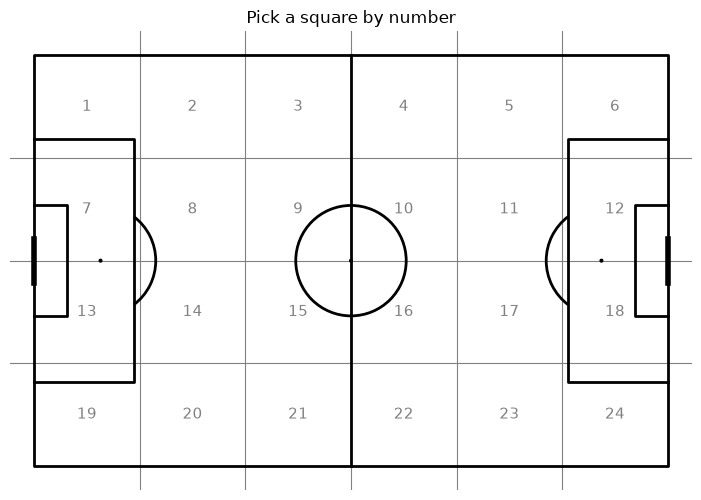

Output()

In [128]:
build_pitch_click_explorer(df)

# Human baseline

Predict the next event yourself, given the same 3-events-of-history context
the MLP (`mlp.ipynb`) sees, and get scored the same way you'd score the
model: accuracy for the categorical fields (`is_home`, `event`, `result`),
MAE for the numeric ones (`start_x`, `start_y`, `time_elapsed`, `duration`).

This reads `data/masked_df.csv` and `data/category_lookup.json` directly —
the same files `mlp.ipynb` trains on — rather than `stage.csv`, so the field
encoding (discretized x/y, integer event/result codes) matches the model
exactly. Ground truth for the current event is reconstructed from the
`step=6` row of each `(game_id, index)` group — by then every field except
`result` has been revealed, and `target` at that step is the true `result`.
Examples are restricted to real actions (excludes the synthetic
`kick_off`/`half_end`/`full_end` markers) with a full, non-boundary 3-event
history, so the task matches a typical mid-sequence prediction the model
would face.

In [129]:
import json

ml_df = pd.read_csv('data/masked_df.csv', index_col=0)
ml_df.loc[ml_df['target'] == -2, 'target'] = 106

with open('data/category_lookup.json') as f:
    quiz_lookup = json.load(f)
quiz_lookup = {col: {int(k): v for k, v in mapping.items()} for col, mapping in quiz_lookup.items()}

EVENT_COLS = ['is_home', 'event', 'start_x', 'start_y', 'time_elapsed', 'duration', 'result']
BOUNDARY_EVENT_CODES = {0, 18, 21}  # kick_off, half_end, full_end
GUESS_COLOR = 'gold'

In [130]:
def build_ground_truth_table(ml_df):
    """One row per (game_id, index) event, with its full ground-truth 7-field
    tuple and its previous-3-event context, reconstructed from the step=6
    masked row (6 current-event fields revealed + target = the 7th, result)."""
    gt = ml_df[ml_df.step == 6].copy()
    gt = gt.drop(columns=['result']).rename(columns={'target': 'result'})
    return gt.set_index(['game_id', 'index'])


def get_clean_events(ground_truth):
    """Events with a real current-action type and a full, non-boundary
    3-event history — a clean, typical mid-sequence prediction task."""
    return ground_truth[
        (~ground_truth['event'].isin(BOUNDARY_EVENT_CODES))
        & (ground_truth['is_home-1'] != -2)
        & (ground_truth['is_home-2'] != -2)
        & (ground_truth['is_home-3'] != -2)
    ]


def get_candidate_examples(ground_truth, n=10, seed=42):
    return get_clean_events(ground_truth).sample(n=n, random_state=seed)

In [131]:
def make_prediction_widget(row):
    """Render the previous 3 events on a pitch (annotated with h,e,x,y,t,d,a),
    plus a live marker showing where your current x/y guess actually is on
    the pitch, and build the input widgets for guessing the current event's
    fields. Returns (output_widget, inputs) — the pitch redraws itself
    whenever the x/y guess widgets change."""
    pitch = Pitch(pitch_type='uefa', line_zorder=2, line_color='black')
    fig, (ax, text_ax) = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={'width_ratios': [1.3, 1]})
    pitch.draw(ax=ax)
    text_ax.axis('off')

    prev = [{
        'is_home': row[f'is_home-{k}'], 'event': row[f'event-{k}'],
        'start_x': row[f'start_x-{k}'], 'start_y': row[f'start_y-{k}'],
        'time_elapsed': row[f'time_elapsed-{k}'], 'duration': row[f'duration-{k}'],
        'result': row[f'result-{k}'],
    } for k in (3, 2, 1)]  # oldest to most recent

    xs = [p['start_x'] for p in prev]
    ys = [p['start_y'] for p in prev]
    colors = [HOME_COLOR if p['is_home'] else AWAY_COLOR for p in prev]
    ax.plot(xs, ys, color='grey', lw=1.5, alpha=0.6, zorder=1)
    ax.scatter(xs, ys, c=colors, s=[120, 180, 260], alpha=[0.5, 0.75, 1.0], zorder=2, edgecolors='black', linewidths=1)
    for k, x, y in zip((-3, -2, -1), xs, ys):
        ax.annotate(str(k), (x, y), ha='center', va='center', fontsize=8, color='white', fontweight='bold', zorder=3)

    # a side text panel, not on-pitch annotations, since consecutive events
    # can land on the same discretized (x, y) and overlapping on-pitch text
    # becomes illegible — this stays readable regardless
    lines = [
        f"{k}:  h={quiz_lookup['is_home'][p['is_home']]}\n"
        f"     e={quiz_lookup['event'][p['event']]}\n"
        f"     x={p['start_x']}, y={p['start_y']}\n"
        f"     t={p['time_elapsed']}, d={p['duration']}, a={quiz_lookup['result'].get(p['result'], p['result'])}\n"
        for k, p in zip((-3, -2, -1), prev)
    ]
    text_ax.text(0.0, 1.0, '\n'.join(lines), transform=text_ax.transAxes, va='top', ha='left', fontsize=10, family='monospace')

    ax.set_title(
        f"period {row.period_id}  {row.minute:02.0f}:{row.second:02.0f}   "
        f"score {row.home_goal_count}-{row.away_goal_count}   "
        f"cards H:{row.home_yellow_count}y/{row.home_red_count}r A:{row.away_yellow_count}y/{row.away_red_count}r",
        fontsize=9,
    )
    fig.suptitle('Predict the NEXT event  (gold ✕ = your x/y guess)', fontsize=11)
    fig.tight_layout()

    real_event_names = {code: name for code, name in quiz_lookup['event'].items() if code not in BOUNDARY_EVENT_CODES}
    result_names = {code: name for code, name in quiz_lookup['result'].items() if code != -2}

    x_widget = widgets.BoundedIntText(value=52, min=0, max=105, description='x')
    y_widget = widgets.BoundedIntText(value=34, min=0, max=68, description='y')

    guess_marker = ax.scatter([x_widget.value], [y_widget.value], marker='X', s=220,
                               color=GUESS_COLOR, edgecolors='black', linewidths=1.5, zorder=5)
    guess_label = ax.annotate('your guess', (x_widget.value, y_widget.value), textcoords='offset points',
                               xytext=(8, 8), fontsize=8, color='#8a6d00', fontweight='bold', zorder=5)
    plt.close(fig)  # detach from pyplot's auto-display; we show it manually below

    out = widgets.Output()

    def redraw():
        with out:
            out.clear_output(wait=True)
            display(fig)

    def on_xy_change(change):
        x, y = x_widget.value, y_widget.value
        guess_marker.set_offsets([[x, y]])
        guess_label.xy = (x, y)
        redraw()

    x_widget.observe(on_xy_change, names='value')
    y_widget.observe(on_xy_change, names='value')
    redraw()

    inputs = {
        'is_home': widgets.Dropdown(options=[('away', 0), ('home', 1)], description='home?'),
        'event': widgets.Dropdown(options=sorted((name, code) for code, name in real_event_names.items()), description='event'),
        'start_x': x_widget,
        'start_y': y_widget,
        'time_elapsed': widgets.BoundedIntText(value=1, min=0, max=105, description='t elapsed'),
        'duration': widgets.BoundedIntText(value=1, min=0, max=68, description='duration'),
        'result': widgets.Dropdown(options=sorted((name, code) for code, name in result_names.items()), description='result'),
    }
    return out, inputs

In [132]:
def score_predictions(guesses, truths):
    """guesses/truths: lists of dicts with the 7 event_cols (one per example).
    Accuracy for is_home/event/result, MAE for start_x/start_y/time_elapsed/duration —
    same function works for scoring the MLP's own predictions on these examples."""
    acc_fields = ['is_home', 'event', 'result']
    mae_fields = ['start_x', 'start_y', 'time_elapsed', 'duration']

    scores = {}
    for f in acc_fields:
        correct = [g[f] == t[f] for g, t in zip(guesses, truths)]
        scores[f] = {'metric': 'accuracy', 'value': sum(correct) / len(correct)}
    for f in mae_fields:
        errors = [abs(g[f] - t[f]) for g, t in zip(guesses, truths)]
        scores[f] = {'metric': 'MAE', 'value': sum(errors) / len(errors)}
    return pd.DataFrame(scores).T


def build_answer_table(guesses, truths):
    """Long-format your-guess-vs-correct-answer table, one row per
    (example, field), for reviewing what you got right/wrong after scoring."""
    label_fields = ['is_home', 'event', 'result']
    rows = []
    for i, (g, t) in enumerate(zip(guesses, truths), start=1):
        for f in EVENT_COLS:
            if f in label_fields:
                your_guess = quiz_lookup[f].get(g[f], g[f])
                answer = quiz_lookup[f].get(t[f], t[f])
            else:
                your_guess = g[f]
                answer = t[f]
            rows.append({
                'example': i,
                'field': f,
                'your_guess': your_guess,
                'answer': answer,
                'correct': g[f] == t[f],
            })
    return pd.DataFrame(rows).set_index(['example', 'field'])

In [133]:
def build_quiz(ml_df, n=10, seed=42):
    """Assemble n prediction examples with a final 'Score my predictions'
    button. Returns the display box plus (inputs, truths, examples) so the
    same 10 examples/ground truths can be reused to score the MLP itself."""
    ground_truth = build_ground_truth_table(ml_df)
    examples = get_candidate_examples(ground_truth, n=n, seed=seed)

    all_inputs = []
    truths = []
    blocks = []
    for i, (_, row) in enumerate(examples.iterrows()):
        fig_out, inputs = make_prediction_widget(row)
        truths.append({f: row[f] for f in EVENT_COLS})
        all_inputs.append(inputs)

        header = widgets.HTML(f"<h4>Example {i + 1} of {len(examples)}</h4>")
        input_box = widgets.HBox(list(inputs.values()))
        blocks.append(widgets.VBox([header, fig_out, input_box]))

    results_out = widgets.Output()

    def on_score(_):
        guesses = [{f: inp[f].value for f in EVENT_COLS} for inp in all_inputs]
        results = score_predictions(guesses, truths)
        answers = build_answer_table(guesses, truths)
        with results_out:
            results_out.clear_output(wait=True)
            display(results)
            with pd.option_context('display.max_rows', None):
                display(answers)

    score_btn = widgets.Button(description='Score my predictions', button_style='success')
    score_btn.on_click(on_score)

    quiz_box = widgets.VBox(blocks + [score_btn, results_out])
    return quiz_box, all_inputs, truths, examples

In [134]:
quiz_box, quiz_inputs, quiz_truths, quiz_examples = build_quiz(ml_df)
display(quiz_box)

100% is home accuracy
50% event accuracy
50% result accuracy
x,y MAE of 16.5
duraation MAE of 0.6
time_elapsed MAE of 4.6

## MLP performance on the same terms

Load the trained checkpoint (`data/mlp_checkpoint.pt`) and evaluate it on
`quiz_examples`/`quiz_truths` from the human baseline above, scored with the
same `score_predictions` function — a direct, apples-to-apples comparison.

The model predicts its 7 fields the same way `mlp.ipynb`'s own `sample_event`
does: starting from a fully-masked current event (`step=0`), it fills in
`is_home` → `event` → `start_x` → `start_y` → `time_elapsed` → `duration` →
`result` one at a time, feeding each prediction back in before predicting the
next field (so it conditions on its own is_home/event/x/y before guessing
duration/result, matching the causal per-field design in `mlp.ipynb`). The
one difference: **argmax instead of multinomial sampling** — a deterministic
best guess per field, comparable to a single human guess, rather than a
stochastic draw.

In [135]:
import torch

with open('data/event_masks.json') as f:
    quiz_masks = json.load(f)
quiz_masks = {col: [106 if v == -2 else v for v in vals] for col, vals in quiz_masks.items()}

MODEL_INPUT_COLS = [
    'is_home', 'event', 'start_x', 'start_y', 'time_elapsed', 'duration', 'result',
    'period_id', 'minute', 'second', 'home_goal_count', 'away_goal_count',
    'home_red_count', 'away_red_count', 'home_yellow_count', 'away_yellow_count',
    'is_home-1', 'event-1', 'start_x-1', 'start_y-1', 'time_elapsed-1', 'duration-1', 'result-1',
    'is_home-2', 'event-2', 'start_x-2', 'start_y-2', 'time_elapsed-2', 'duration-2', 'result-2',
    'is_home-3', 'event-3', 'start_x-3', 'start_y-3', 'time_elapsed-3', 'duration-3', 'result-3',
]


def load_mlp_weights(path='data/mlp_checkpoint.pt'):
    checkpoint = torch.load(path)
    return checkpoint['W1'], checkpoint['b1'], checkpoint['W2'], checkpoint['b2']

In [136]:
def get_model_input_rows(ml_df, examples):
    """The step=0 row for each (game_id, index) in examples — all 7
    current-event fields masked as -1, exactly what the model receives
    before predicting anything (a fair, from-scratch comparison to the
    human, who also sees no partial reveal)."""
    step0 = ml_df[ml_df.step == 0].set_index(['game_id', 'index'])
    return step0.loc[examples.index]


@torch.no_grad()
def mlp_predict_event(x_row, W1, b1, W2, b2, masks):
    """Greedily (argmax) fill in the 7 masked event fields in order —
    mlp.ipynb's sample_event, but argmax instead of multinomial sampling."""
    x = x_row.clone()
    for i, field in enumerate(EVENT_COLS):
        logits = torch.relu(x @ W1 + b1) @ W2 + b2
        mask = torch.tensor(masks[field])
        best = logits[:, mask].argmax(dim=1).item()
        value = mask[best].item()
        x[0, i] = -2 if value == 106 else value
    return {field: x[0, i].item() for i, field in enumerate(EVENT_COLS)}


@torch.no_grad()
def evaluate_mlp(ml_df, examples, W1, b1, W2, b2, masks):
    model_inputs = get_model_input_rows(ml_df, examples)
    guesses = []
    for _, row in model_inputs.iterrows():
        x = torch.tensor(row[MODEL_INPUT_COLS].values.astype(float)).float().unsqueeze(0)
        guesses.append(mlp_predict_event(x, W1, b1, W2, b2, masks))
    return guesses

In [137]:
W1, b1, W2, b2 = load_mlp_weights()
mlp_guesses = evaluate_mlp(ml_df, quiz_examples, W1, b1, W2, b2, quiz_masks)
mlp_scores = score_predictions(mlp_guesses, quiz_truths)
mlp_scores

,metric,value
is_home,accuracy,0.6
event,accuracy,0.6
result,accuracy,0.7
start_x,MAE,16.3
start_y,MAE,18.9
time_elapsed,MAE,4.4
duration,MAE,0.7


## MLP performance on the actual validation set

`n=10` above is a nice apples-to-apples spot check, but it's too small to say
much about real model performance. This runs the same evaluation over
`mlp.ipynb`'s actual held-out validation split — not a fresh re-sample, since
that notebook's train/val/test split isn't seeded (`events_shuffled =
ml_events.sample(frac=1)` has no `random_state`), so re-deriving it here
wouldn't reproduce the exact games the model was actually validated on.
Instead, run this cell in `mlp.ipynb`, right after `df_shuffled2` is built,
to persist the exact split in memory:

```python
df_shuffled2.to_csv('data/val_set.csv', index=False)
```

Then come back here. Since this is tens of thousands of events rather than
10, the per-example autoregressive loop (`mlp_predict_event`) would be slow
— `mlp_predict_events_batch` below does the same 7-field autoregressive
prediction but vectorized across all events at once (7 forward passes total,
not 7 × N), verified to produce identical results to the per-row version.

In [138]:
@torch.no_grad()
def mlp_predict_events_batch(X, W1, b1, W2, b2, masks):
    """Vectorized version of mlp_predict_event — all N events' 7 fields
    predicted in parallel, autoregressively across fields (7 forward passes
    total, not 7*N): is_home, then event, then x, ... each conditioning on
    the fields already filled in for that same event."""
    X = X.clone()
    for i, field in enumerate(EVENT_COLS):
        logits = torch.relu(X @ W1 + b1) @ W2 + b2
        mask = torch.tensor(masks[field])
        restricted = logits[:, mask]
        best = restricted.argmax(dim=1)
        values = mask[best]
        values = torch.where(values == 106, torch.tensor(-2), values)
        X[:, i] = values.float()
    return X[:, :len(EVENT_COLS)]

In [139]:
val_df = pd.read_csv('data/val_set.csv')
val_df.loc[val_df['target'] == -2, 'target'] = 106

val_ground_truth = build_ground_truth_table(val_df)
val_clean = get_clean_events(val_ground_truth)
print(f'{len(val_clean):,} clean events out of {len(val_ground_truth):,} total in the val split')

val_model_inputs = get_model_input_rows(val_df, val_clean)
Xval_quiz = torch.tensor(val_model_inputs[MODEL_INPUT_COLS].values.astype(float)).float()

val_preds = mlp_predict_events_batch(Xval_quiz, W1, b1, W2, b2, quiz_masks)
val_guesses = [dict(zip(EVENT_COLS, row.tolist())) for row in val_preds]
val_truths = [{f: r[f] for f in EVENT_COLS} for _, r in val_clean.iterrows()]

val_scores = score_predictions(val_guesses, val_truths)
val_scores

74,489 clean events out of 74,831 total in the val split


,metric,value
is_home,accuracy,0.808442
event,accuracy,0.654338
result,accuracy,0.827505
start_x,MAE,12.006135
start_y,MAE,9.606371
time_elapsed,MAE,1.976654
duration,MAE,0.918283


## Summary: human vs. zeroed-input baseline vs. trained model

Same val-set events (`Xval_quiz`/`val_truths`, the clean, real-action events
with a full 3-event history from the actual validation split), same
autoregressive full-event prediction, same `score_predictions` metric —
just swapping in each model's weights. The human numbers are the ones you
self-reported after the 10-example quiz above, not recomputed here (there's
no stored record of your individual guesses, only the printed summary) —
and that quiz drew its 10 examples from the full dataset, not the val split
specifically, so treat the human row as a rough reference point, not a
strictly apples-to-apples n for n comparison.

Loss (binary cross-entropy, the actual training objective) only makes sense
for the two trained models — a human guess isn't a probability
distribution, so there's nothing to plug into BCE for the human row.

In [140]:
baseline_checkpoint = torch.load('data/mlp_baseline_checkpoint.pt')
W1_baseline, b1_baseline, W2_baseline, b2_baseline = (
    baseline_checkpoint['W1'], baseline_checkpoint['b1'],
    baseline_checkpoint['W2'], baseline_checkpoint['b2'],
)

baseline_preds = mlp_predict_events_batch(Xval_quiz, W1_baseline, b1_baseline, W2_baseline, b2_baseline, quiz_masks)
baseline_guesses = [dict(zip(EVENT_COLS, row.tolist())) for row in baseline_preds]
baseline_val_scores = score_predictions(baseline_guesses, val_truths)
baseline_val_scores

,metric,value
is_home,accuracy,0.518399
event,accuracy,0.430332
result,accuracy,0.169434
start_x,MAE,53.096216
start_y,MAE,32.912739
time_elapsed,MAE,2.198445
duration,MAE,0.897126


In [141]:
# loss values are exact numbers from mlp.ipynb's full no-grad forward pass
# over the complete Xval/Yval (split_loss('val') and baseline_val_loss) —
# not recomputed here since explore_stage.ipynb only builds the step=0
# slice of the val set (Xval_quiz), not the full multi-step tensor needed
# for a single-field BCE loss.
baseline_val_loss = 0.041101
trained_val_loss = 0.023910

fields_ordered = ['loss', 'is_home', 'event', 'result', 'start_x', 'start_y', 'time_elapsed', 'duration']
metric_labels = {
    'loss': 'BCE loss', 'is_home': 'accuracy', 'event': 'accuracy', 'result': 'accuracy',
    'start_x': 'MAE', 'start_y': 'MAE', 'time_elapsed': 'MAE', 'duration': 'MAE',
}

# self-reported from the quiz above (f2fca2bc) — x/y were combined into one figure there
human = {
    'loss': None, 'is_home': 1.00, 'event': 0.50, 'result': 0.50,
    'start_x': 16.5, 'start_y': 16.5, 'time_elapsed': 4.6, 'duration': 0.6,
}
baseline = {'loss': baseline_val_loss, **baseline_val_scores['value'].to_dict()}
trained = {'loss': trained_val_loss, **val_scores['value'].to_dict()}

summary = pd.DataFrame({
    'metric': [metric_labels[f] for f in fields_ordered],
    'human (n=10, self-reported)': [human[f] for f in fields_ordered],
    f'zeroed-input baseline (val, n={len(val_clean):,})': [baseline[f] for f in fields_ordered],
    f'trained model (val, n={len(val_clean):,})': [trained[f] for f in fields_ordered],
}, index=fields_ordered)
summary

,metric,"human (n=10, self-reported)","zeroed-input baseline (val, n=74,489)","trained model (val, n=74,489)"
loss,BCE loss,NaN,0.041101,0.023910
is_home,accuracy,1.0,0.518399,0.808442
event,accuracy,0.5,0.430332,0.654338
result,accuracy,0.5,0.169434,0.827505
start_x,MAE,16.5,53.096216,12.006135
start_y,MAE,16.5,32.912739,9.606371
time_elapsed,MAE,4.6,2.198445,1.976654
duration,MAE,0.6,0.897126,0.918283


## Accuracy by event type

Not just overall `event`-field accuracy, but broken down per type — e.g.
does the model actually distinguish a `shot` from a `dribble`, or does its
65% overall accuracy come from nailing a couple of dominant types and
missing everything else? Uses the same autoregressive val predictions
(`val_guesses`/`baseline_guesses`/`val_truths`) from the sections above.

In [ ]:
def event_type_accuracy(guesses, truths):
    """Per-event-type accuracy for the event field: of the events that were
    truly type X, what fraction did the model correctly call X (recall per class)."""
    true_events = [t['event'] for t in truths]
    pred_events = [g['event'] for g in guesses]

    rows = []
    for code, name in sorted(quiz_lookup['event'].items(), key=lambda kv: kv[1]):
        if code in BOUNDARY_EVENT_CODES:
            continue
        matches = [te == code for te in true_events]
        n = sum(matches)
        if n == 0:
            continue
        correct = sum(pe == te for pe, te, m in zip(pred_events, true_events, matches) if m)
        rows.append({'event_type': name, 'n': n, 'accuracy': correct / n})

    return pd.DataFrame(rows).set_index('event_type')

In [ ]:
baseline_event_accuracy = event_type_accuracy(baseline_guesses, val_truths)
trained_event_accuracy = event_type_accuracy(val_guesses, val_truths)

event_accuracy_comparison = pd.DataFrame({
    'n': baseline_event_accuracy['n'],
    'zeroed_baseline_accuracy': baseline_event_accuracy['accuracy'],
    'trained_model_accuracy': trained_event_accuracy['accuracy'],
}).sort_values('n', ascending=False)
event_accuracy_comparison

## Predicted vs. true event type distribution

How often the model predicts each event type, next to how often it actually
occurs — makes the class-collapse from the accuracy breakdown above
concrete: does the model ever predict the rare types, or does it just
never say "shot"/"tackle"/etc. regardless of what's true?

In [ ]:
def event_type_rate(items):
    """Occurrence rate of each event type in a list of event dicts (either
    guesses or truths) — how often is this event type predicted / how often
    does it actually occur."""
    counts = pd.Series([d['event'] for d in items]).value_counts()
    total = len(items)

    rows = []
    for code, name in quiz_lookup['event'].items():
        if code in BOUNDARY_EVENT_CODES:
            continue
        rows.append({'event_type': name, 'n': counts.get(code, 0), 'rate': counts.get(code, 0) / total})

    return pd.DataFrame(rows).set_index('event_type')

In [ ]:
true_rate = event_type_rate(val_truths)
baseline_rate = event_type_rate(baseline_guesses)
trained_rate = event_type_rate(val_guesses)

event_type_comparison = pd.DataFrame({
    'true_rate': true_rate['rate'],
    'zeroed_baseline_predicted_rate': baseline_rate['rate'],
    'trained_model_predicted_rate': trained_rate['rate'],
}).sort_values('true_rate', ascending=False)
event_type_comparison

## Does the same collapse happen on is_home and result?

Generalizes the event-type analysis above to any categorical field —
predicted vs. true rate *and* per-class accuracy in one table, for
`is_home` and `result` too.

In [ ]:
def field_rate(items, field):
    """Occurrence rate of each value of a categorical field (is_home, event,
    or result) in a list of event dicts (guesses or truths)."""
    exclude = BOUNDARY_EVENT_CODES if field == 'event' else {-2}
    counts = pd.Series([d[field] for d in items]).value_counts()
    total = len(items)

    rows = []
    for code, name in quiz_lookup[field].items():
        if code in exclude:
            continue
        rows.append({field: name, 'n': counts.get(code, 0), 'rate': counts.get(code, 0) / total})

    return pd.DataFrame(rows).set_index(field)


def field_accuracy(guesses, truths, field):
    """Per-class accuracy (recall) for a categorical field: of the events
    truly value X, what fraction did the model correctly call X."""
    exclude = BOUNDARY_EVENT_CODES if field == 'event' else {-2}
    true_vals = [t[field] for t in truths]
    pred_vals = [g[field] for g in guesses]

    rows = []
    for code, name in quiz_lookup[field].items():
        if code in exclude:
            continue
        matches = [tv == code for tv in true_vals]
        n = sum(matches)
        if n == 0:
            continue
        correct = sum(pv == tv for pv, tv, m in zip(pred_vals, true_vals, matches) if m)
        rows.append({field: name, 'n': n, 'accuracy': correct / n})

    return pd.DataFrame(rows).set_index(field)


def field_comparison(guesses, field):
    true_r = field_rate(val_truths, field)
    baseline_r = field_rate(baseline_guesses, field)
    trained_r = field_rate(guesses, field)
    baseline_a = field_accuracy(baseline_guesses, val_truths, field)
    trained_a = field_accuracy(guesses, val_truths, field)

    return pd.DataFrame({
        'true_rate': true_r['rate'],
        'zeroed_baseline_predicted_rate': baseline_r['rate'],
        'trained_model_predicted_rate': trained_r['rate'],
        'zeroed_baseline_accuracy': baseline_a['accuracy'],
        'trained_model_accuracy': trained_a['accuracy'],
    }).sort_values('true_rate', ascending=False)

In [ ]:
is_home_comparison = field_comparison(val_guesses, 'is_home')
is_home_comparison

In [ ]:
result_comparison = field_comparison(val_guesses, 'result')
result_comparison

## Coverage of the numeric fields: start_x, start_y, time_elapsed, duration

Same question as the categorical collapse above, applied to the
continuous-ish fields — does the model spread its predictions across the
full observed range, or does it also default toward a narrow band of
values regardless of context? `nunique`/`std` give a quick numeric read;
the histograms make it visual.

In [ ]:
def numeric_coverage_stats(field):
    true_vals = pd.Series([t[field] for t in val_truths])
    baseline_vals = pd.Series([g[field] for g in baseline_guesses])
    trained_vals = pd.Series([g[field] for g in val_guesses])

    return {
        'true_unique': true_vals.nunique(),
        'baseline_unique': baseline_vals.nunique(),
        'trained_unique': trained_vals.nunique(),
        'true_std': true_vals.std(),
        'baseline_std': baseline_vals.std(),
        'trained_std': trained_vals.std(),
    }


numeric_fields = ['start_x', 'start_y', 'time_elapsed', 'duration']
numeric_coverage = pd.DataFrame({f: numeric_coverage_stats(f) for f in numeric_fields}).T
numeric_coverage

In [ ]:
def plot_numeric_field_distributions(fields=numeric_fields, bins=40):
    """True vs predicted value distributions for each numeric field — shows
    whether predictions spread across the full range of observed values or
    collapse onto a narrow band. The zeroed baseline always predicts one
    constant value, so it's shown as a reference line rather than a
    histogram — a single-value histogram is just a spike that would crush
    the y-axis scale for everything else."""
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))

    for ax, field in zip(axes.flat, fields):
        true_vals = [t[field] for t in val_truths]
        baseline_vals = [g[field] for g in baseline_guesses]
        trained_vals = [g[field] for g in val_guesses]

        ax.hist(true_vals, bins=bins, alpha=0.5, density=True, color='grey', label='true')
        ax.hist(trained_vals, bins=bins, alpha=0.5, density=True, color='steelblue', label='trained model')
        ax.axvline(baseline_vals[0], color='crimson', linewidth=2, linestyle='--', label='zeroed baseline (constant)')
        ax.set_title(field)
        ax.legend(fontsize=8)

    fig.tight_layout()
    return fig


plot_numeric_field_distributions()
plt.show()